In [1]:
# =====================================================
# TP 1 — Introduction aux modèles génératifs
# Partie 1.1 — Question 1 : simuler une Bernoulli (N = 1000, true_p = 0.7)
# =====================================================
import torch                         # calcul avec gradients automatiques
import torch.optim as optim          # optimiseurs (descente de gradient)
import torch.nn.functional as F      # fonctions utiles (softplus)
import numpy as np                   # calcul numérique
import matplotlib.pyplot as plt      # graphiques

torch.manual_seed(0)                                   # même hasard à chaque exécution
true_p = 0.7                                           # vrai paramètre
N = 1000                                               # taille de l'échantillon
data = torch.bernoulli(true_p * torch.ones(N, 1))      # 1000 valeurs 0 ou 1
print(f"Proportion de 1 dans l'échantillon : {data.mean().item():.4f}")

Proportion de 1 dans l'échantillon : 0.7010


In [2]:
# =====================================================
# Partie 1.1 — Question 2 : estimer θ par descente de gradient (θ0 = 0.5)
# =====================================================
theta = torch.tensor([0.5], requires_grad=True)     # θ commence à 0.5 ; PyTorch calculera sa dérivée
optimizer = optim.SGD([theta], lr=0.1)              # descente de gradient avec un pas de 0.1

hist_theta, hist_nll = [], []                       # pour garder θ et la NLL à chaque itération

for epoch in range(200):                            # 200 itérations
    nll = -(data * torch.log(theta)                 # NLL = -moyenne[ x log θ + (1-x) log(1-θ) ]
            + (1 - data) * torch.log(1 - theta)).mean()
    optimizer.zero_grad()                           # efface l'ancien gradient
    nll.backward()                                  # calcule dNLL/dθ
    optimizer.step()                                # met à jour θ
    with torch.no_grad():
        theta.clamp_(1e-3, 1 - 1e-3)                # clamp : θ reste entre 0 et 1
    hist_theta.append(theta.item())                 # sauvegarde θ
    hist_nll.append(nll.item())                     # sauvegarde la NLL

print(f"θ après 1 itération    : {hist_theta[0]:.4f}")
print(f"θ après 10 itérations  : {hist_theta[9]:.4f}")
print(f"θ final (200 itér.)    : {theta.item():.4f}")
print(f"NLL initiale           : {hist_nll[0]:.4f}")
print(f"NLL finale             : {hist_nll[-1]:.4f}")

θ après 1 itération    : 0.5804
θ après 10 itérations  : 0.7005
θ final (200 itér.)    : 0.7010
NLL initiale           : 0.6931
NLL finale             : 0.6100


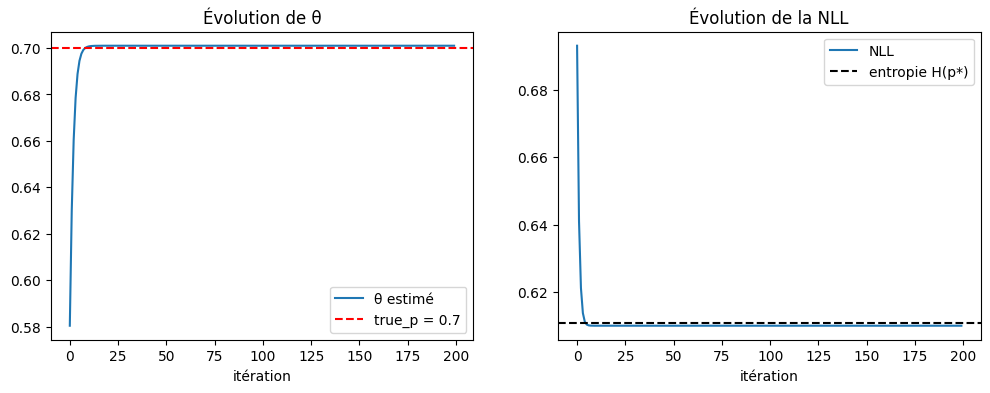

In [3]:
# =====================================================
# Partie 1.1 — Question 3 : tracer l'évolution de θ et de la NLL
# =====================================================
H = -(true_p * np.log(true_p) + (1 - true_p) * np.log(1 - true_p))  # entropie H(p*) : NLL minimale théorique

fig, ax = plt.subplots(1, 2, figsize=(12, 4))          # 2 graphiques côte à côte
ax[0].plot(hist_theta, label="θ estimé")               # courbe de θ
ax[0].axhline(true_p, color="r", ls="--", label="true_p = 0.7")
ax[0].set_title("Évolution de θ"); ax[0].set_xlabel("itération"); ax[0].legend()
ax[1].plot(hist_nll, label="NLL")                      # courbe de la NLL
ax[1].axhline(H, color="k", ls="--", label="entropie H(p*)")
ax[1].set_title("Évolution de la NLL"); ax[1].set_xlabel("itération"); ax[1].legend()
plt.show()


In [4]:
# =====================================================
# Partie 1.1 — Question 4 : comparer θ estimé, true_p et θ̂_MLE
# =====================================================
theta_mle = data.mean().item()                          # estimateur analytique : θ̂_MLE = moyenne x̄
print(f"Valeur vraie true_p      = {true_p}")
print(f"Estimateur analytique x̄  = {theta_mle:.4f}")
print(f"Descente de gradient     = {theta.item():.4f}")
print(f"Écart gradient / MLE     = {abs(theta.item() - theta_mle):.6f}")
print(f"Écart gradient / true_p  = {abs(theta.item() - true_p):.6f}")

Valeur vraie true_p      = 0.7
Estimateur analytique x̄  = 0.7010
Descente de gradient     = 0.7010
Écart gradient / MLE     = 0.000000
Écart gradient / true_p  = 0.001000


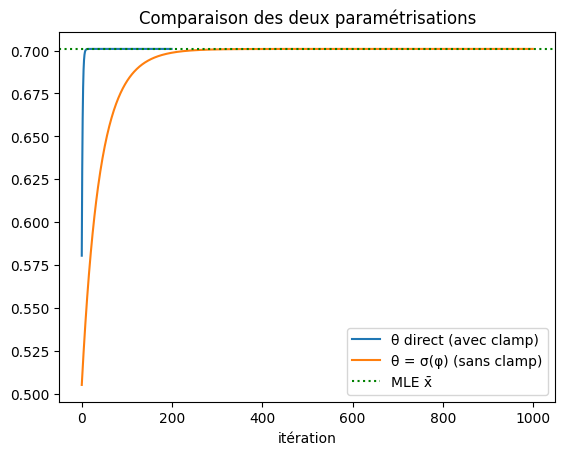

θ final avec clamp    : 0.7010
θ final avec sigmoïde : 0.7010
φ final               : 0.8521


In [5]:
# =====================================================
# Partie 1.1 — Question 5 : reparamétrisation θ = σ(φ) (sans clamp)
# =====================================================
phi = torch.tensor([0.0], requires_grad=True)          # φ libre dans R ; σ(0) = 0.5 donc même départ
optimizer = optim.SGD([phi], lr=0.1)                   # même pas que la question 2

hist_theta_s = []                                      # historique de θ = σ(φ)
for epoch in range(1000):                              # plus d'itérations : le gradient σ(φ) - x̄ est plus petit
    theta_s = torch.sigmoid(phi)                       # θ = σ(φ), toujours entre 0 et 1
    nll = -(data * torch.log(theta_s)
            + (1 - data) * torch.log(1 - theta_s)).mean()
    optimizer.zero_grad()
    nll.backward()                                     # gradient dNLL/dφ = σ(φ) - x̄
    optimizer.step()                                   # aucun clamp nécessaire
    hist_theta_s.append(torch.sigmoid(phi).item())

plt.plot(hist_theta, label="θ direct (avec clamp)")
plt.plot(hist_theta_s, label="θ = σ(φ) (sans clamp)")
plt.axhline(theta_mle, color="g", ls=":", label="MLE x̄")
plt.xlabel("itération"); plt.title("Comparaison des deux paramétrisations"); plt.legend()
plt.show()

print(f"θ final avec clamp    : {theta.item():.4f}")
print(f"θ final avec sigmoïde : {torch.sigmoid(phi).item():.4f}")
print(f"φ final               : {phi.item():.4f}")

In [6]:
# =====================================================
# Partie 1.2 — Gaussienne univariée
# Question 1 : simuler N = 2000 observations de N(μ = 2.0, σ = 1.5)
# =====================================================
torch.manual_seed(0)                                   # même hasard à chaque exécution
mu_true, sigma_true, N = 2.0, 1.5, 2000                # vrais paramètres et taille
data = mu_true + sigma_true * torch.randn(N)           # randn ~ N(0,1), décalé de μ et étiré de σ

print(f"Nombre d'observations : {len(data)}")
print(f"Moyenne empirique     : {data.mean().item():.4f}")
print(f"Écart-type empirique  : {data.std(unbiased=False).item():.4f}")

Nombre d'observations : 2000
Moyenne empirique     : 2.0227
Écart-type empirique  : 1.5327


In [7]:
# =====================================================
# Partie 1.2 — Question 2 : NLL moyenne de la gaussienne univariée
# NLL = moyenne[ log σ + ½ log(2π) + (x - μ)² / (2σ²) ]
# =====================================================
def nll_gauss_1d(data, mu, sigma):
    nll = (torch.log(sigma)                                # log σ
           + 0.5 * torch.log(2 * torch.tensor(torch.pi))   # ½ log(2π)
           + (data - mu)**2 / (2 * sigma**2))              # (x - μ)² / (2σ²)
    return nll.mean()                                      # moyenne sur les observations

# Petit test : NLL avec les vrais paramètres
print(f"NLL avec les vrais paramètres (μ=2, σ=1.5) : "
      f"{nll_gauss_1d(data, torch.tensor(2.0), torch.tensor(1.5)).item():.4f}")
print(f"NLL avec de mauvais paramètres (μ=0, σ=1)  : "
      f"{nll_gauss_1d(data, torch.tensor(0.0), torch.tensor(1.0)).item():.4f}")

NLL avec les vrais paramètres (μ=2, σ=1.5) : 1.8466
NLL avec de mauvais paramètres (μ=0, σ=1)  : 4.1391


In [8]:
# =====================================================
# Partie 1.2 — Question 3 : optimiser μ et ρ par descente de gradient
# σ = softplus(ρ) + ε  garantit σ > 0
# =====================================================
mu  = torch.tensor([0.0], requires_grad=True)          # μ commence à 0
rho = torch.tensor([0.0], requires_grad=True)          # ρ libre dans R
optimizer = optim.Adam([mu, rho], lr=0.05)             # optimiseur Adam (comme dans le cours)

mus, sigmas, losses = [], [], []                       # historiques pour la question 4
for epoch in range(300):
    sigma = F.softplus(rho) + 1e-6                     # σ = log(1 + e^ρ) + ε, toujours > 0
    loss = nll_gauss_1d(data, mu, sigma)               # NLL avec les paramètres actuels
    optimizer.zero_grad()
    loss.backward()                                    # gradients par rapport à μ et ρ
    optimizer.step()                                   # mise à jour de μ et ρ
    mus.append(mu.item()); sigmas.append(sigma.item()); losses.append(loss.item())

print(f"μ final    : {mu.item():.4f}")
print(f"σ final    : {sigmas[-1]:.4f}")
print(f"NLL finale : {losses[-1]:.4f}")

μ final    : 2.0227
σ final    : 1.5329
NLL finale : 1.8460


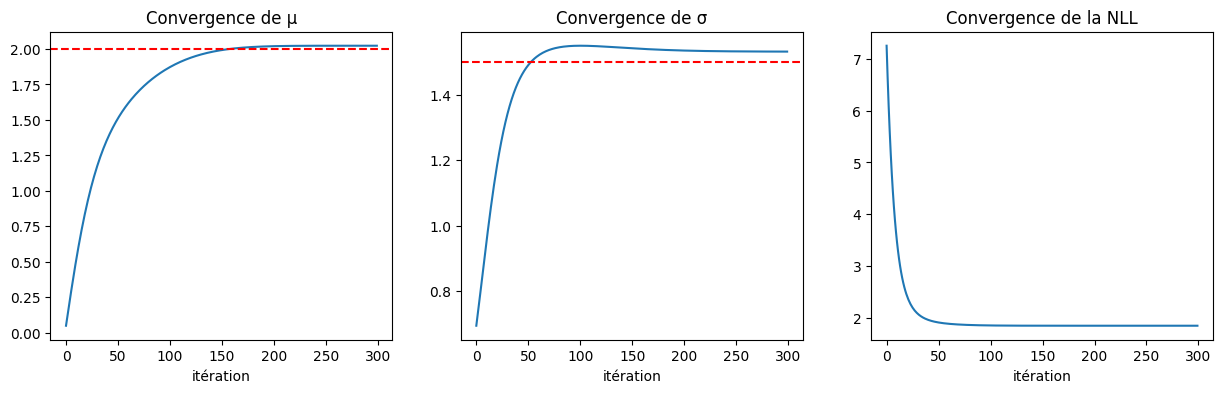

In [9]:
# =====================================================
# Partie 1.2 — Question 4 : courbes de convergence de μ, σ et de la NLL
# =====================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 4))          # 3 graphiques côte à côte
ax[0].plot(mus);    ax[0].axhline(mu_true, color="r", ls="--");    ax[0].set_title("Convergence de μ")
ax[1].plot(sigmas); ax[1].axhline(sigma_true, color="r", ls="--"); ax[1].set_title("Convergence de σ")
ax[2].plot(losses); ax[2].set_title("Convergence de la NLL")
for a in ax:
    a.set_xlabel("itération")
plt.show()

In [10]:
# =====================================================
# Partie 1.2 — Question 5 : comparer les paramètres estimés aux valeurs vraies
# =====================================================
sigma_est = (F.softplus(rho) + 1e-6).item()            # σ estimé final
print(f"μ : vrai = {mu_true} | estimé = {mu.item():.4f} | analytique (moyenne) = {data.mean().item():.4f}")
print(f"σ : vrai = {sigma_true} | estimé = {sigma_est:.4f} | analytique (écart-type) = {data.std(unbiased=False).item():.4f}")

μ : vrai = 2.0 | estimé = 2.0227 | analytique (moyenne) = 2.0227
σ : vrai = 1.5 | estimé = 1.5329 | analytique (écart-type) = 1.5327


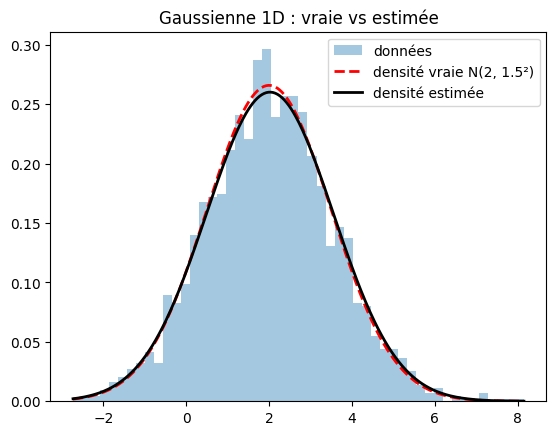

In [11]:
# =====================================================
# Partie 1.2 — Question 6 : histogramme des données + densité vraie + densité estimée
# =====================================================
def densite(x, m, s):                                  # densité de la loi normale N(m, s²)
    return np.exp(-(x - m)**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi))

xs = np.linspace(data.min().item(), data.max().item(), 400)   # 400 points pour tracer les courbes
plt.hist(data.numpy(), bins=50, density=True, alpha=0.4, label="données")   # histogramme normalisé
plt.plot(xs, densite(xs, mu_true, sigma_true), "r--", lw=2, label="densité vraie N(2, 1.5²)")
plt.plot(xs, densite(xs, mu.item(), sigma_est), "k", lw=2, label="densité estimée")
plt.title("Gaussienne 1D : vraie vs estimée"); plt.legend()
plt.show()

In [12]:
# =====================================================
# Partie 1.2 — Gaussienne multivariée (d = 3)
# Question 1 : générer N = 2000 observations de N(μ_true, Σ_true)
# =====================================================
torch.manual_seed(0)
d, N = 3, 2000                                         # dimension 3, 2000 observations
mu_true = torch.tensor([2.0, -1.0, 0.5])               # vraie moyenne
Sigma_true = torch.tensor([[2.0,  0.8,  0.3],          # vraie covariance (symétrique,
                           [0.8,  1.0, -0.4],          #  définie positive, avec des
                           [0.3, -0.4,  1.5]])         #  corrélations + et -)
loi = torch.distributions.MultivariateNormal(mu_true, Sigma_true)
data = loi.sample((N,))                                # 2000 vecteurs de dimension 3

print("Forme des données :", data.shape)               # (2000, 3)
print("Moyenne empirique :", data.mean(dim=0).numpy().round(3))
print("Covariance empirique :\n", torch.cov(data.T, correction=0).numpy().round(3))

Forme des données : torch.Size([2000, 3])
Moyenne empirique : [ 1.984 -1.028  0.508]
Covariance empirique :
 [[ 1.973  0.774  0.307]
 [ 0.774  0.979 -0.397]
 [ 0.307 -0.397  1.512]]


In [13]:
# =====================================================
# Partie 1.2 — Question 2 : NLL moyenne de la gaussienne multivariée
# NLL = d/2 log(2π) + ½ log|Σ| + ½ (x-μ)ᵀ Σ⁻¹ (x-μ),   avec Σ = L Lᵀ (Cholesky)
# =====================================================
def nll_gauss_multi(data, mu, L):
    d = data.shape[1]
    diff = (data - mu).T                                         # x - μ, taille (d, N)
    y = torch.linalg.solve_triangular(L, diff, upper=False)      # résout L y = x - μ (sans inverser Σ)
    quad = (y**2).sum(dim=0)                                     # (x-μ)ᵀ Σ⁻¹ (x-μ)
    logdet = 2 * torch.log(torch.diagonal(L)).sum()              # log|Σ| = 2 Σ log L_ii
    nll = 0.5 * d * torch.log(2 * torch.tensor(torch.pi)) + 0.5 * logdet + 0.5 * quad
    return nll.mean()

# Petit test : NLL avec les vrais paramètres vs une gaussienne standard
L_vrai = torch.linalg.cholesky(Sigma_true)                       # facteur de Cholesky de Σ_true
print(f"NLL avec les vrais paramètres  : {nll_gauss_multi(data, mu_true, L_vrai).item():.4f}")
print(f"NLL avec μ = 0 et Σ = I        : {nll_gauss_multi(data, torch.zeros(3), torch.eye(3)).item():.4f}")

NLL avec les vrais paramètres  : 4.4346
NLL avec μ = 0 et Σ = I        : 7.6144


In [14]:
# =====================================================
# Partie 1.2 — Question 3 : estimation par gradient de μ et de L
# L triangulaire inférieure à diagonale positive  =>  Σ = L Lᵀ définie positive
# =====================================================
def construire_L(L_raw):
    diag = F.softplus(torch.diagonal(L_raw)) + 1e-6              # diagonale > 0
    return torch.tril(L_raw, diagonal=-1) + torch.diag(diag)     # triangulaire inférieure

mu = torch.zeros(d, requires_grad=True)                          # μ commence à (0, 0, 0)
L_raw = torch.zeros(d, d, requires_grad=True)                    # matrice libre 3x3
optimizer = optim.Adam([mu, L_raw], lr=0.05)

hist_mu, hist_diag, hist_nll = [], [], []                        # historiques pour la question 4
for epoch in range(1500):
    L = construire_L(L_raw)
    loss = nll_gauss_multi(data, mu, L)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        Sigma = L @ L.T                                          # Σ = L Lᵀ
        hist_mu.append(mu.clone().numpy())
        hist_diag.append(torch.diagonal(Sigma).numpy().copy())
        hist_nll.append(loss.item())

with torch.no_grad():
    L = construire_L(L_raw)
    Sigma_est = L @ L.T
print("μ estimé :", mu.detach().numpy().round(3))
print("Σ estimée :\n", Sigma_est.numpy().round(3))
print(f"NLL finale : {hist_nll[-1]:.4f}")

μ estimé : [ 1.984 -1.028  0.508]
Σ estimée :
 [[ 1.973  0.774  0.307]
 [ 0.774  0.979 -0.397]
 [ 0.307 -0.397  1.512]]
NLL finale : 4.4340


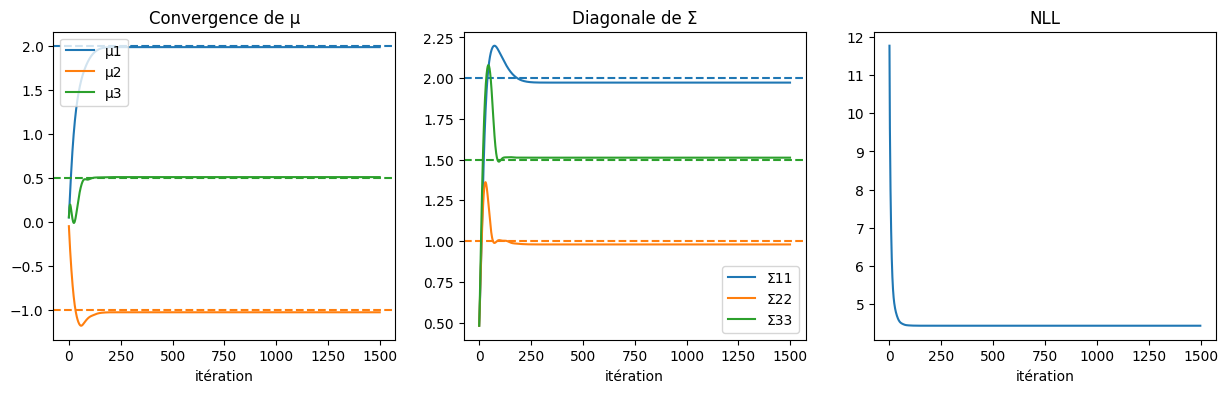

In [15]:
# =====================================================
# Partie 1.2 — Question 4 : convergence de μ, de la diagonale de Σ et de la NLL
# =====================================================
hist_mu = np.array(hist_mu)                            # (1500, 3)
hist_diag = np.array(hist_diag)                        # (1500, 3)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j in range(d):
    ax[0].plot(hist_mu[:, j], label=f"μ{j+1}")
    ax[0].axhline(mu_true[j], ls="--", color=f"C{j}")             # vraie valeur en pointillés
    ax[1].plot(hist_diag[:, j], label=f"Σ{j+1}{j+1}")
    ax[1].axhline(Sigma_true[j, j], ls="--", color=f"C{j}")
ax[2].plot(hist_nll)
ax[0].set_title("Convergence de μ"); ax[1].set_title("Diagonale de Σ"); ax[2].set_title("NLL")
ax[0].legend(); ax[1].legend()
for a in ax:
    a.set_xlabel("itération")
plt.show()

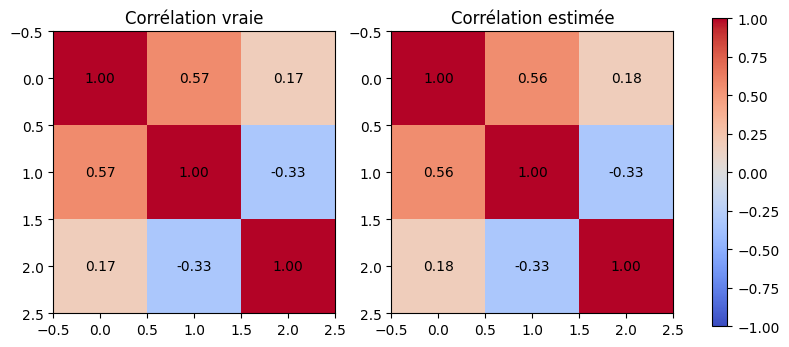

In [16]:
# =====================================================
# Partie 1.2 — Question 5 : heatmaps des corrélations vraie et estimée
# corrélation ρ_ij = Σ_ij / (σ_i σ_j)
# =====================================================
def correlation(S):
    s = torch.sqrt(torch.diagonal(S))                  # écarts-types
    return S / torch.outer(s, s)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, S, titre in zip(ax, [Sigma_true, Sigma_est], ["Corrélation vraie", "Corrélation estimée"]):
    C = correlation(S).numpy()
    im = a.imshow(C, cmap="coolwarm", vmin=-1, vmax=1) # bleu = négatif, rouge = positif
    for i in range(d):
        for j in range(d):
            a.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center")   # valeur dans chaque case
    a.set_title(titre)
fig.colorbar(im, ax=ax)
plt.show()

Forme de X : (6000, 3)
Proportion de points par composante : [0.501 0.295 0.204]


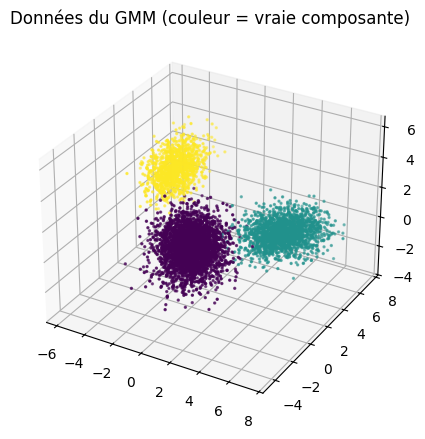

In [17]:
# =====================================================
# Partie 1.3 — Mélange de gaussiennes (GMM) et algorithme EM
# Question 1 : générer un GMM avec K = 3, d = 3, N = 6000
# =====================================================
rng = np.random.default_rng(0)                         # générateur aléatoire (reproductible)
K, d, N = 3, 3, 6000                                   # 3 composantes, dimension 3, 6000 points

pi_true = np.array([0.5, 0.3, 0.2])                    # vrais poids des composantes (somme = 1)
mu_true = np.array([[ 0.0, 0.0, 0.0],                  # vraie moyenne de la composante 0
                    [ 4.0, 4.0, 0.0],                  # composante 1
                    [-3.0, 3.0, 3.0]])                 # composante 2
Sigma_true = np.array([np.eye(3),                      # vraies covariances
                       [[1.0, 0.5, 0.0], [0.5, 1.0, 0.0], [0.0, 0.0, 0.5]],
                       [[0.6, 0.0, 0.2], [0.0, 1.2, 0.0], [0.2, 0.0, 0.8]]])

z_true = rng.choice(K, size=N, p=pi_true)              # composante de chaque point (variable latente)
X = np.array([rng.multivariate_normal(mu_true[k], Sigma_true[k]) for k in z_true])   # les 6000 points

print("Forme de X :", X.shape)
print("Proportion de points par composante :", (np.bincount(z_true) / N).round(3))

ax = plt.figure(figsize=(6, 5)).add_subplot(projection="3d")   # nuage en 3D, coloré par composante
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=z_true, s=2, cmap="viridis")
ax.set_title("Données du GMM (couleur = vraie composante)")
plt.show()

In [18]:
# =====================================================
# Partie 1.3 — Question 2 : initialisation du GMM
# poids uniformes, moyennes aléatoires, covariances régulières
# =====================================================
rng_init = np.random.default_rng(1)                    # autre graine pour l'initialisation

pi = np.ones(K) / K                                    # poids uniformes : 1/3, 1/3, 1/3
mu = X[rng_init.choice(N, K, replace=False)].copy()    # moyennes = 3 points de X pris au hasard
Sigma = np.array([np.cov(X.T)] * K)                    # covariances = covariance globale des données (régulière)

print("Poids initiaux :", pi.round(3))
print("Moyennes initiales :\n", mu.round(2))

Poids initiaux : [0.333 0.333 0.333]
Moyennes initiales :
 [[-4.11  2.29  3.08]
 [-3.38  2.87  4.12]
 [-0.48  1.49 -0.74]]


In [19]:
# =====================================================
# Partie 1.3 — Question 3 : algorithme EM jusqu'à convergence (ou 200 itérations max)
# =====================================================
def log_gauss(X, m, S):                                # log N(x | m, S) pour tous les points
    L = np.linalg.cholesky(S)                          # S = L Lᵀ
    y = np.linalg.solve(L, (X - m).T)                  # résout L y = x - m
    quad = (y**2).sum(axis=0)                          # (x-m)ᵀ S⁻¹ (x-m)
    logdet = 2 * np.log(np.diag(L)).sum()              # log|S|
    return -0.5 * (X.shape[1] * np.log(2 * np.pi) + logdet + quad)

hist_ll = []                                           # log-vraisemblance moyenne à chaque itération
for it in range(200):
    # ---- E-step : responsabilités r_ik = π_k N(x_i|μ_k,Σ_k) / Σ_j π_j N(x_i|μ_j,Σ_j) ----
    log_joint = np.stack([np.log(pi[k]) + log_gauss(X, mu[k], Sigma[k]) for k in range(K)], axis=1)
    m = log_joint.max(axis=1, keepdims=True)           # astuce log-sum-exp (stabilité numérique)
    log_px = m + np.log(np.exp(log_joint - m).sum(axis=1, keepdims=True))   # log p(x_i)
    r = np.exp(log_joint - log_px)                     # responsabilités, taille (N, K)
    hist_ll.append(log_px.mean())                      # log-vraisemblance moyenne

    # ---- M-step : mise à jour des paramètres ----
    Nk = r.sum(axis=0)                                 # N_k = Σ_i r_ik
    pi = Nk / N                                        # π_k = N_k / N
    mu = (r.T @ X) / Nk[:, None]                       # μ_k = Σ_i r_ik x_i / N_k
    for k in range(K):
        D = X - mu[k]
        Sigma[k] = (r[:, k:k+1] * D).T @ D / Nk[k] + 1e-6 * np.eye(d)   # Σ_k (+ petite régularisation)

    if it > 0 and abs(hist_ll[-1] - hist_ll[-2]) < 1e-6:   # arrêt si la log-vraisemblance ne bouge plus
        break

print(f"Convergence après {it + 1} itérations")
print(f"Log-vraisemblance moyenne : début = {hist_ll[0]:.4f} | fin = {hist_ll[-1]:.4f}")

Convergence après 43 itérations
Log-vraisemblance moyenne : début = -7.1341 | fin = -5.0479


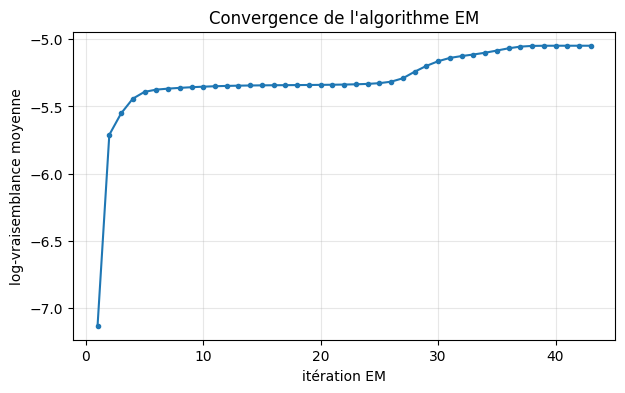

La log-vraisemblance diminue-t-elle à un moment ? non


In [20]:
# =====================================================
# Partie 1.3 — Question 4 : évolution de la log-vraisemblance au cours des itérations EM
# =====================================================
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(hist_ll) + 1), hist_ll, "o-", markersize=3)
plt.xlabel("itération EM")
plt.ylabel("log-vraisemblance moyenne")
plt.title("Convergence de l'algorithme EM")
plt.grid(alpha=0.3)
plt.show()

diffs = np.diff(hist_ll)                               # variation d'une itération à la suivante
print(f"La log-vraisemblance diminue-t-elle à un moment ? {'oui' if (diffs < -1e-9).any() else 'non'}")

In [21]:
# =====================================================
# Partie 1.3 — Question 5 : comparer poids, moyennes et covariances estimés aux vrais
# =====================================================
print("Poids vrais     :", pi_true)
print("Poids estimés   :", pi.round(3))
print()
print("Moyennes vraies :\n", mu_true)
print("Moyennes estimées :\n", mu.round(2))

Poids vrais     : [0.5 0.3 0.2]
Poids estimés   : [0.5   0.205 0.295]

Moyennes vraies :
 [[ 0.  0.  0.]
 [ 4.  4.  0.]
 [-3.  3.  3.]]
Moyennes estimées :
 [[-0.    0.01  0.01]
 [-3.    2.96  2.97]
 [ 3.98  3.96 -0.  ]]


In [22]:
# =====================================================
# Partie 1.3 — Question 6 : label switching et alignement des composantes
# =====================================================
from scipy.optimize import linear_sum_assignment       # algorithme hongrois (meilleure correspondance)

# distance entre chaque vraie moyenne (lignes) et chaque moyenne estimée (colonnes)
distances = np.linalg.norm(mu_true[:, None, :] - mu[None, :, :], axis=2)
_, ordre = linear_sum_assignment(distances)            # ordre[k] = composante estimée associée à la vraie k
print("Correspondance vraie -> estimée :", {k: int(ordre[k]) for k in range(K)})

pi_al, mu_al, Sigma_al = pi[ordre], mu[ordre], Sigma[ordre]   # paramètres estimés réordonnés

print("\nPoids vrais   :", pi_true)
print("Poids alignés :", pi_al.round(3))
print("\nMoyennes alignées :\n", mu_al.round(2))
for k in range(K):
    erreur = np.abs(Sigma_al[k] - Sigma_true[k]).max()
    print(f"Composante {k} : écart max entre Σ vraie et Σ estimée = {erreur:.3f}")

Correspondance vraie -> estimée : {0: 0, 1: 2, 2: 1}

Poids vrais   : [0.5 0.3 0.2]
Poids alignés : [0.5   0.295 0.205]

Moyennes alignées :
 [[-0.    0.01  0.01]
 [ 3.98  3.96 -0.  ]
 [-3.    2.96  2.97]]
Composante 0 : écart max entre Σ vraie et Σ estimée = 0.052
Composante 1 : écart max entre Σ vraie et Σ estimée = 0.018
Composante 2 : écart max entre Σ vraie et Σ estimée = 0.085


In [23]:
# =====================================================
# Partie 1.3 — Question 6 : discussion (réponse écrite)
# =====================================================
# Label switching : dans un GMM, permuter les composantes (k <-> j) donne exactement
# la même vraisemblance, car p(x) = Σ_k π_k N(x | μ_k, Σ_k) est une somme dont l'ordre
# des termes ne compte pas. Il existe donc K! = 6 solutions équivalentes, et EM converge
# vers l'une d'elles selon l'initialisation. Ici, les composantes estimées 1 et 2 sont
# inversées par rapport aux vraies (poids 0.205 et 0.295 au lieu de 0.3 et 0.2).
#
# Procédure d'alignement : on calcule la distance entre chaque vraie moyenne et chaque
# moyenne estimée, puis on cherche la correspondance une-à-une qui minimise la distance
# totale (algorithme hongrois, linear_sum_assignment). On obtient {0: 0, 1: 2, 2: 1}.
# Après réordonnancement, les poids (0.5, 0.295, 0.205), les moyennes et les covariances
# (écart max <= 0.085) sont très proches des paramètres vrais : EM a bien retrouvé le
# mélange, à une permutation près.
print("Réponse de la question 6 ajoutée.")

Réponse de la question 6 ajoutée.


Forme de X : (300, 2)


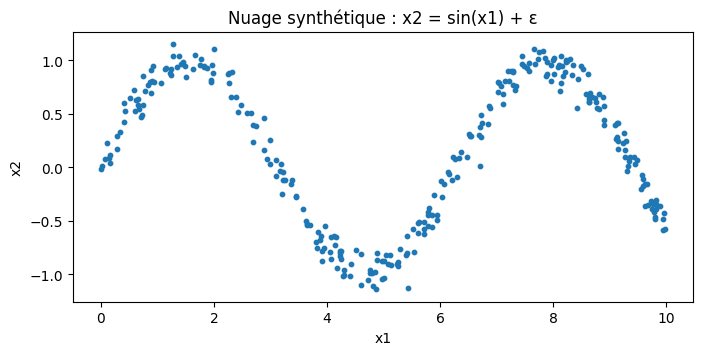

In [24]:
# =====================================================
# Partie 1.4 — GMM sur un nuage synthétique 2D
# Question 1 : générer 300 points avec x2 = sin(x1) + ε, puis visualiser
# =====================================================
rng = np.random.default_rng(0)
n_samples = 300
x1 = rng.uniform(0, 10, n_samples)                     # x1 uniforme dans [0, 10]
eps = rng.normal(0, 0.1, n_samples)                    # bruit ε ~ N(0, 0.1)
x2 = np.sin(x1) + eps                                  # x2 = sin(x1) + ε
X2d = np.column_stack([x1, x2])                        # matrice X de taille (300, 2)

print("Forme de X :", X2d.shape)

plt.figure(figsize=(8, 3.5))
plt.scatter(X2d[:, 0], X2d[:, 1], s=10)
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("Nuage synthétique : x2 = sin(x1) + ε")
plt.show()

In [25]:
# =====================================================
# Partie 1.4 — Question 2 : ajuster un GaussianMixture (6 composantes)
# =====================================================
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=6, covariance_type="full", random_state=0)   # 6 gaussiennes, covariances pleines
gmm.fit(X2d)                                           # algorithme EM sur les 300 points

print("Convergence :", gmm.converged_, "en", gmm.n_iter_, "itérations")
print("Poids des composantes :", gmm.weights_.round(3))
print("Moyennes (x1, x2) :\n", gmm.means_.round(2))
print(f"Log-vraisemblance moyenne : {gmm.score(X2d):.3f}")

Convergence : True en 16 itérations
Poids des composantes : [0.115 0.175 0.22  0.132 0.201 0.158]
Moyennes (x1, x2) :
 [[ 8.02  0.93]
 [ 2.89  0.19]
 [ 6.33  0.04]
 [ 4.51 -0.87]
 [ 9.27  0.13]
 [ 0.79  0.65]]
Log-vraisemblance moyenne : -1.549


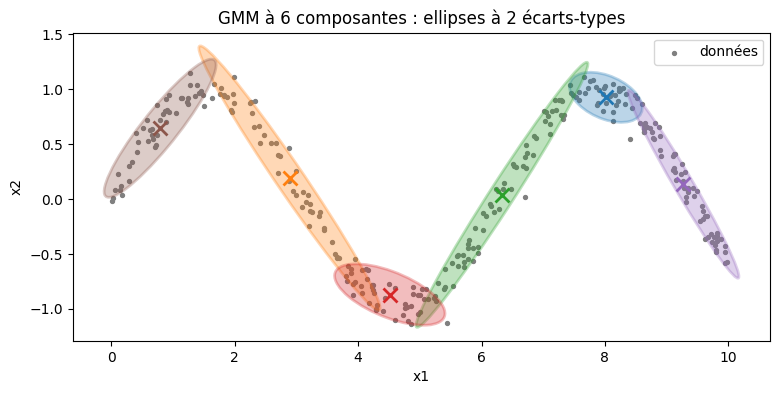

In [26]:
# =====================================================
# Partie 1.4 — Question 3 : composantes gaussiennes en ellipses sur le nuage
# =====================================================
from matplotlib.patches import Ellipse

def dessiner_ellipse(ax, moyenne, cov, couleur, n_std=2.0):
    valeurs, vecteurs = np.linalg.eigh(cov)                         # valeurs/vecteurs propres de Σ
    angle = np.degrees(np.arctan2(vecteurs[1, 1], vecteurs[0, 1]))  # orientation du grand axe
    largeur, hauteur = 2 * n_std * np.sqrt(valeurs[::-1])           # longueurs des axes (2 écarts-types)
    ax.add_patch(Ellipse(moyenne, largeur, hauteur, angle=angle,
                         facecolor=couleur, alpha=0.3, edgecolor=couleur, lw=2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(X2d[:, 0], X2d[:, 1], s=8, color="gray", label="données")
couleurs = plt.cm.tab10(np.arange(6))
for k in range(6):
    dessiner_ellipse(ax, gmm.means_[k], gmm.covariances_[k], couleurs[k])
    ax.plot(*gmm.means_[k], "x", color=couleurs[k], markersize=10, mew=2)   # centre de la composante
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("GMM à 6 composantes : ellipses à 2 écarts-types")
ax.legend()
plt.show()

Forme des points générés : (200, 2)
Nombre de points par composante : [24 39 39 28 38 32]


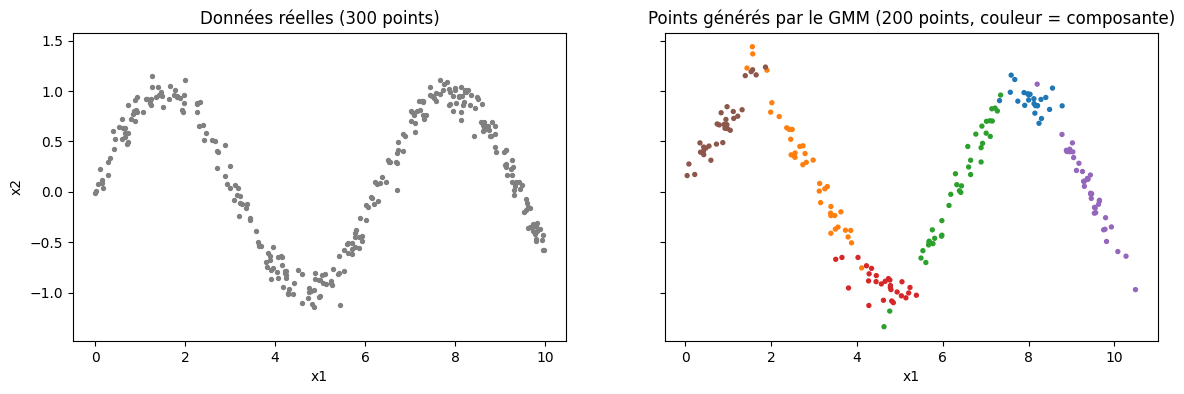

In [27]:
# =====================================================
# Partie 1.4 — Question 4 : échantillonner 200 points depuis le mélange appris
# =====================================================
X_gen, comp_gen = gmm.sample(200)                      # 200 nouveaux points + la composante d'origine de chacun

print("Forme des points générés :", X_gen.shape)
print("Nombre de points par composante :", np.bincount(comp_gen, minlength=6))

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax[0].scatter(X2d[:, 0], X2d[:, 1], s=8, color="gray")
ax[0].set_title("Données réelles (300 points)")
ax[1].scatter(X_gen[:, 0], X_gen[:, 1], s=8, c=comp_gen, cmap="tab10", vmin=0, vmax=9)
ax[1].set_title("Points générés par le GMM (200 points, couleur = composante)")
for a in ax:
    a.set_xlabel("x1")
ax[0].set_ylabel("x2")
plt.show()

Composante 0 : moyenne = [8.02 0.93], poids = 0.115


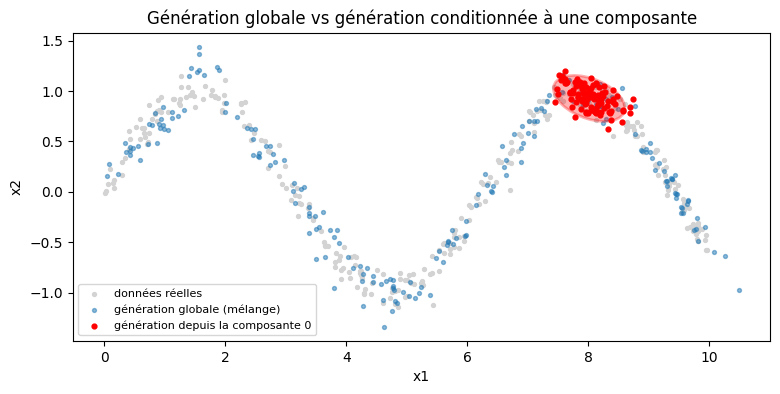

In [28]:
# =====================================================
# Partie 1.4 — Question 5 : 100 points depuis la composante i = 0 seulement
# =====================================================
i = 0
rng = np.random.default_rng(0)
X_comp = rng.multivariate_normal(gmm.means_[i], gmm.covariances_[i], size=100)   # tirage dans N(μ_i, Σ_i)

print(f"Composante {i} : moyenne = {gmm.means_[i].round(2)}, poids = {gmm.weights_[i]:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(X2d[:, 0], X2d[:, 1], s=8, color="lightgray", label="données réelles")
ax.scatter(X_gen[:, 0], X_gen[:, 1], s=8, color="C0", alpha=0.5, label="génération globale (mélange)")
ax.scatter(X_comp[:, 0], X_comp[:, 1], s=12, color="red", label=f"génération depuis la composante {i}")
dessiner_ellipse(ax, gmm.means_[i], gmm.covariances_[i], "red")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)
ax.set_title("Génération globale vs génération conditionnée à une composante")
plt.show()

# ---- Discussion ----
# Génération globale : on tire d'abord une composante k selon les poids π_k, puis un point
# dans N(μ_k, Σ_k). Les points couvrent alors toute la vague : on reproduit la distribution
# complète des données, p(x) = Σ_k π_k N(x | μ_k, Σ_k).
# Génération conditionnée : on fixe la composante i, donc on tire dans p(x | z = i) = N(μ_i, Σ_i).
# Les 100 points restent concentrés dans un seul morceau de la vague (l'ellipse rouge) :
# on contrôle QUELLE région est générée, mais on perd la diversité de l'ensemble.
# La variable latente z (l'indice de la composante) joue donc le rôle d'un « bouton de contrôle »
# de la génération, idée qu'on retrouve dans les modèles conditionnels (CVAE, GAN conditionnel).

100%|██████████| 9.91M/9.91M [00:00<00:00, 39.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.10MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.98MB/s]


Forme de la matrice des images : (5000, 784)
Dimension d d'une image vectorisée : 784


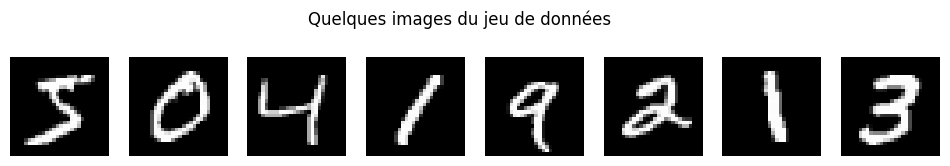

In [29]:
# =====================================================
# Partie 2 — Génération d'images par modèle gaussien et variable latente
# 2.1 — Question 1 : charger N images et les vectoriser (x ∈ R^d)
# =====================================================
import torchvision

mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True)   # chiffres manuscrits 28x28
N_img = 5000                                           # nombre d'images utilisées
h, w = 28, 28
X_img = mnist.data[:N_img].numpy().reshape(N_img, -1).astype(np.float64) / 255.0   # (5000, 784), pixels entre 0 et 1
d_img = X_img.shape[1]

print("Forme de la matrice des images :", X_img.shape)   # (5000, 784)
print("Dimension d d'une image vectorisée :", d_img)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for j, ax in enumerate(axes):
    ax.imshow(X_img[j].reshape(h, w), cmap="gray"); ax.axis("off")
plt.suptitle("Quelques images du jeu de données")
plt.show()

Forme de μ̂ : (784,)
Forme de Σ̂ : (784, 784)
Σ̂ est-elle symétrique ? True


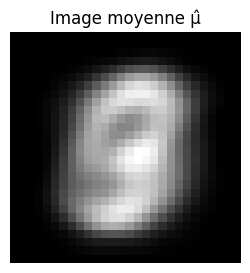

In [30]:
# =====================================================
# 2.1 — Question 2 : moyenne empirique  μ̂ = (1/N) Σ x_i
# =====================================================
mu_img = X_img.mean(axis=0)                            # vecteur de 784 valeurs : la moyenne de chaque pixel

# =====================================================
# 2.1 — Question 3 : covariance empirique  Σ̂ = (1/N) Σ (x_i - μ̂)(x_i - μ̂)ᵀ
# =====================================================
Xc = X_img - mu_img                                    # images centrées
Sigma_img = (Xc.T @ Xc) / N_img                        # matrice 784 x 784

print("Forme de μ̂ :", mu_img.shape)
print("Forme de Σ̂ :", Sigma_img.shape)
print("Σ̂ est-elle symétrique ?", np.allclose(Sigma_img, Sigma_img.T))

# =====================================================
# 2.1 — Question 4 : visualiser l'image moyenne μ̂
# =====================================================
plt.figure(figsize=(3, 3))
plt.imshow(mu_img.reshape(h, w), cmap="gray")
plt.title("Image moyenne μ̂"); plt.axis("off")
plt.show()

Variance expliquée par les 10 premières composantes : 49.3 %
Variance expliquée par les 25 premières composantes : 69.8 %
Variance expliquée par les 50 premières composantes : 82.9 %


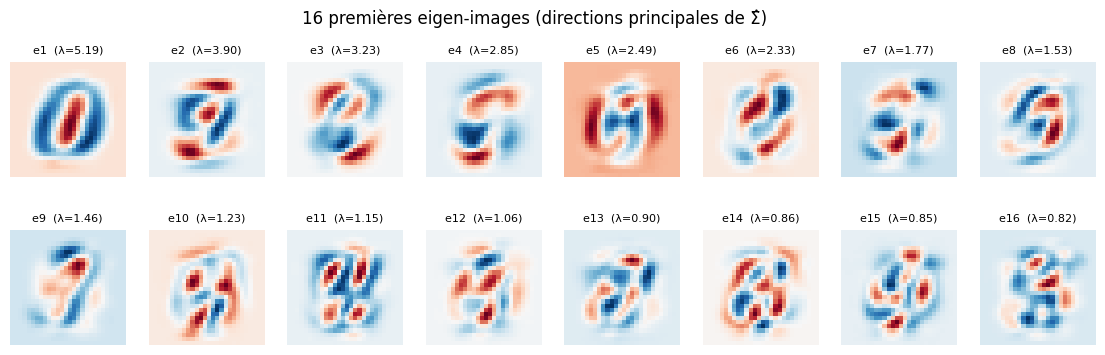

In [31]:
# =====================================================
# 2.1 — Question 5 : décomposition spectrale (ACP) de Σ̂ et premières eigen-images
# =====================================================
valeurs_p, vecteurs_p = np.linalg.eigh(Sigma_img)      # Σ̂ = E Λ Eᵀ (eigh : pour matrices symétriques)
ordre = np.argsort(valeurs_p)[::-1]                    # tri des valeurs propres de la plus grande à la plus petite
Lambda = np.clip(valeurs_p[ordre], 0, None)            # valeurs propres (on enlève d'éventuels petits négatifs numériques)
E = vecteurs_p[:, ordre]                               # vecteurs propres dans le même ordre

variance_cumulee = np.cumsum(Lambda) / Lambda.sum()    # part de variance expliquée par les r premières directions
for r in [10, 25, 50]:
    print(f"Variance expliquée par les {r} premières composantes : {100 * variance_cumulee[r - 1]:.1f} %")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for j, ax in enumerate(axes.flat):
    ax.imshow(E[:, j].reshape(h, w), cmap="RdBu_r")   # rouge = positif, bleu = négatif
    ax.set_title(f"e{j+1}  (λ={Lambda[j]:.2f})", fontsize=8)
    ax.axis("off")
plt.suptitle("16 premières eigen-images (directions principales de Σ̂)")
plt.show()


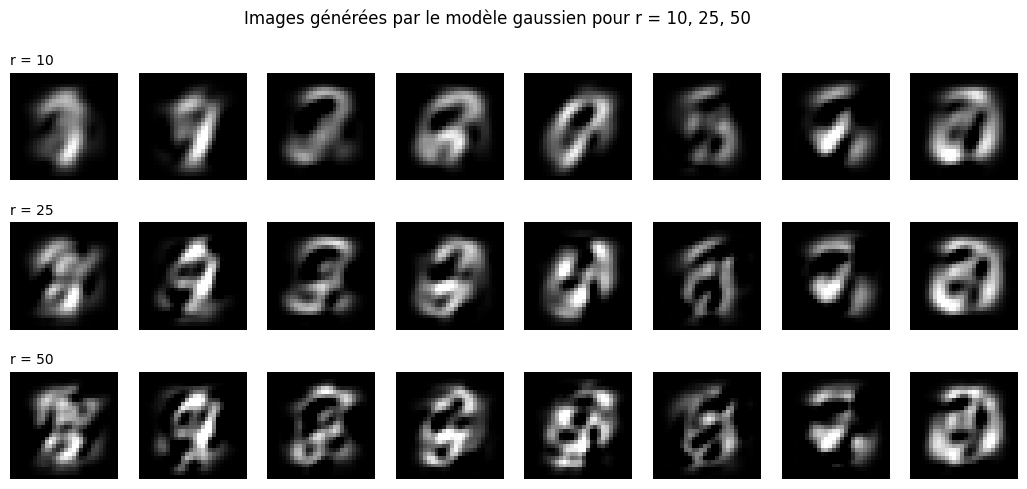

In [32]:
# =====================================================
# 2.1 — Question 6 : générer x = μ̂ + E_r Λ_r^{1/2} z,  z ~ N(0, I_r)
# 2.1 — Question 7 : comparer visuellement pour r ∈ {10, 25, 50}
# =====================================================
rng = np.random.default_rng(0)
n_gen = 8                                              # 8 images générées par valeur de r
Z = rng.standard_normal((n_gen, 50))                   # les mêmes z pour toutes les valeurs de r (comparaison juste)

def generer(r, Z):
    A = E[:, :r] * np.sqrt(Lambda[:r])                 # A = E_r Λ_r^{1/2}, matrice (784, r)
    return mu_img + Z[:, :r] @ A.T                     # x = μ̂ + A z, pour chaque ligne de Z

valeurs_r = [10, 25, 50]
fig, axes = plt.subplots(len(valeurs_r), n_gen, figsize=(13, 5.5))
for ligne, r in enumerate(valeurs_r):
    images = np.clip(generer(r, Z), 0, 1)              # on ramène les pixels dans [0, 1] pour l'affichage
    for j in range(n_gen):
        axes[ligne, j].imshow(images[j].reshape(h, w), cmap="gray", vmin=0, vmax=1)
        axes[ligne, j].axis("off")
    axes[ligne, 0].set_title(f"r = {r}", fontsize=10, loc="left")
plt.suptitle("Images générées par le modèle gaussien pour r = 10, 25, 50")
plt.show()

In [33]:
# =====================================================
# 2.1 — Question 7 : comparaison visuelle selon r
# =====================================================
# Avec r = 10, les images générées sont très floues et proches de l'image moyenne : seules les
# grandes variations (épaisseur globale, forme ronde ou allongée) sont reproduites (49 % de la variance).
# Quand r augmente (25 puis 50, soit 70 % puis 83 % de la variance), les images contiennent davantage
# de détails et de contrastes locaux, mais aussi davantage de « bruit » : les traits sont brouillés,
# fragmentés, et on reconnaît rarement un chiffre précis. Augmenter r ajoute de la variabilité,
# mais pas du réalisme.
#
# =====================================================
# 2.1 — Question 8 : limites du modèle gaussien pour générer des images réalistes
# =====================================================
# 1. Une gaussienne est unimodale (une seule « bosse » autour de μ̂), alors que les images de chiffres
#    forment plusieurs groupes bien distincts (0, 1, ..., 9) : le modèle mélange toutes les classes.
# 2. Le générateur est linéaire : x = μ̂ + A z. Une image générée est une simple somme pondérée
#    d'eigen-images, qui ne peut pas reproduire des structures non linéaires (traits fins et continus).
# 3. Les coefficients z_j sont tirés indépendamment : le modèle ne capture que les corrélations
#    d'ordre 2 (covariance) entre pixels, pas les dépendances plus complexes.
# 4. Les pixels peuvent sortir de [0, 1] et doivent être tronqués ; le fond n'est pas parfaitement noir.
# Ces limites motivent les générateurs non linéaires profonds (VAE, GAN, diffusion).
print("Réponses des questions 7 et 8 ajoutées.")

Réponses des questions 7 et 8 ajoutées.


In [34]:
# =====================================================
# 2.2 — Question 1 : le modèle gaussien définit un générateur affine G(z) = μ̂ + A z
# =====================================================
# La génération s'écrit x = μ̂ + E_r Λ_r^{1/2} z avec z ~ N(0, I_r).
# En posant A = E_r Λ_r^{1/2}, on obtient x = G(z) = μ̂ + A z :
# c'est une fonction AFFINE de z (une partie linéaire A z plus une constante μ̂).
# La loi des images générées est la mesure image de N(0, I_r) par G :
# G(z) ~ N(μ̂, A Aᵀ), et A Aᵀ = E_r Λ_r E_rᵀ ≈ Σ̂ (égalité exacte si r = d).
#
# =====================================================
# 2.2 — Question 2 : identification de la matrice A
# =====================================================
# A = E_r Λ_r^{1/2} : matrice de taille (d, r) = (784, r).
# Sa colonne j vaut √λ_j · e_j : c'est la j-ième eigen-image, multipliée par l'écart-type
# des données dans cette direction.

r = 50
A = E[:, :r] * np.sqrt(Lambda[:r])                     # A = E_r Λ_r^{1/2}
print("Forme de A :", A.shape)                         # (784, 50)
erreur = np.abs(A @ A.T - E[:, :r] @ np.diag(Lambda[:r]) @ E[:, :r].T).max()
print(f"Vérification A Aᵀ = E_r Λ_r E_rᵀ : écart max = {erreur:.2e}")

Forme de A : (784, 50)
Vérification A Aᵀ = E_r Λ_r E_rᵀ : écart max = 8.33e-17


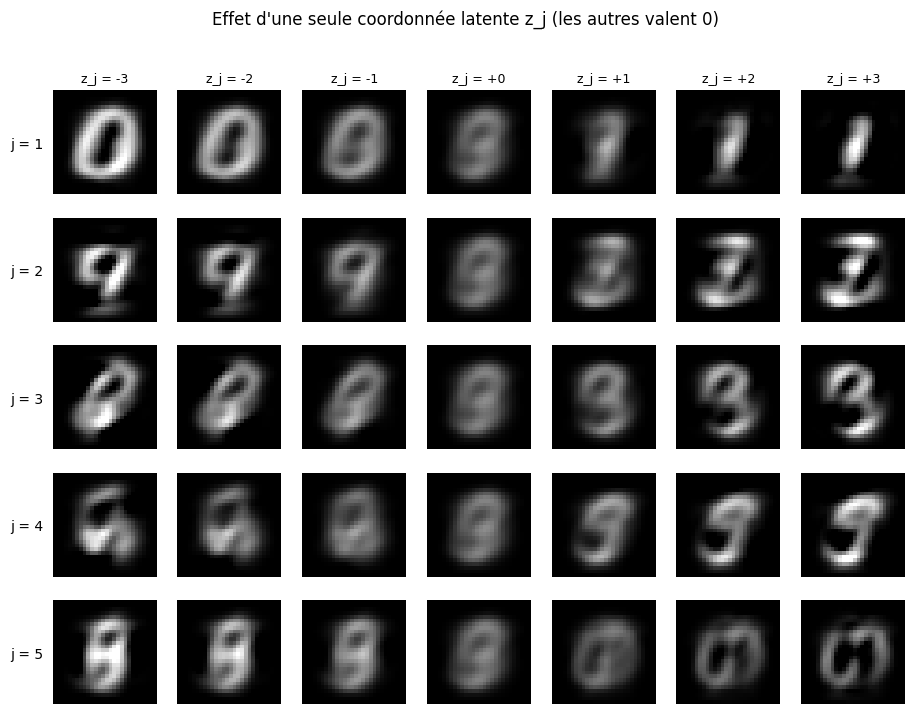

In [35]:
# =====================================================
# 2.2 — Question 3 : faire varier une seule coordonnée de z à la fois
# =====================================================
valeurs_z = np.linspace(-3, 3, 7)                      # z_j = -3, -2, -1, 0, 1, 2, 3
directions = [0, 1, 2, 3, 4]                           # on teste les 5 premières coordonnées

fig, axes = plt.subplots(len(directions), len(valeurs_z), figsize=(11, 8))
for ligne, j in enumerate(directions):
    for col, v in enumerate(valeurs_z):
        z = np.zeros(r); z[j] = v                      # seule la coordonnée j est non nulle
        img = np.clip(mu_img + A @ z, 0, 1)            # G(z) = μ̂ + A z
        axes[ligne, col].imshow(img.reshape(h, w), cmap="gray", vmin=0, vmax=1)
        axes[ligne, col].axis("off")
        if ligne == 0:
            axes[ligne, col].set_title(f"z_j = {v:+.0f}", fontsize=9)
    axes[ligne, 0].text(-12, 14, f"j = {j+1}", fontsize=10, va="center")
plt.suptitle("Effet d'une seule coordonnée latente z_j (les autres valent 0)")
plt.show()

# =====================================================
# 2.2 — Question 4 : interprétation des directions associées aux plus grandes valeurs propres
# =====================================================
# Au centre (z = 0), on retrouve l'image moyenne. Chaque ligne montre un passage continu d'une
# forme à une autre : les premières directions (plus grandes valeurs propres) correspondent aux
# variations les plus importantes des chiffres, par exemple passer d'une forme ronde (type 0)
# à une forme fine et verticale (type 1), ou changer l'inclinaison et la répartition de l'encre.
# Ce sont des variations GLOBALES de toute l'image. Les directions suivantes (plus petites
# valeurs propres) modifient des détails plus locaux et ont un effet plus faible.
#
# =====================================================
# 2.2 — Question 5 : pourquoi ce générateur reste linéaire et en quoi cela limite sa capacité
# =====================================================
# G(z) = μ̂ + A z est une fonction affine : faire varier z_j déplace l'image le long d'une
# ligne droite dans l'espace des pixels (on ajoute v·√λ_j·e_j). Les effets des coordonnées
# s'additionnent simplement, sans interaction. Un tel générateur ne peut produire que des
# images situées dans un sous-espace affine de dimension r et ne peut pas représenter la
# structure non linéaire de l'ensemble des vrais chiffres (qui forment une variété courbée,
# en plusieurs groupes). D'où des images floues ou mélangées. Les générateurs profonds
# (VAE, GAN) remplacent A z par un réseau de neurones non linéaire G_θ(z).

In [36]:
# =====================================================
# Partie 3 — Modèles autorégressifs sur séquences
# 3.1 — Question 1 : tokeniser un petit corpus français (tokeniseur simple)
# =====================================================
import re
from collections import defaultdict, Counter

corpus_texte = """Une souris verte courait dans l'herbe. Une souris grise dormait dans la maison.
Le chat noir regardait la souris verte. Le chat dormait dans le jardin.
Une petite fille jouait dans le jardin avec le chat. La petite fille aimait la souris grise.
Une maison blanche se trouvait près du jardin. Le jardin de la maison était grand.
La souris verte mangeait du fromage dans la maison. Le chat noir aimait le fromage.
Une fille regardait le chat dans le jardin. La maison blanche était calme.
Une souris et un chat jouaient dans l'herbe verte. Le soleil brillait sur le jardin."""

corpus = re.findall(r"\w+|[^\w\s]", corpus_texte)     # découpe en mots et en signes de ponctuation
print("Nombre de tokens :", len(corpus))
print("20 premiers tokens :", corpus[:20])

# =====================================================
# 3.1 — Question 2 : compter les mots uniques et construire un index de vocabulaire
# =====================================================
vocabulaire = sorted(set(corpus))                      # mots uniques, triés
mot2index = {mot: i for i, mot in enumerate(vocabulaire)}   # index : mot -> numéro
print("Nombre de mots uniques :", len(vocabulaire))
print("Extrait de l'index :", dict(list(mot2index.items())[:8]))

Nombre de tokens : 119
20 premiers tokens : ['Une', 'souris', 'verte', 'courait', 'dans', 'l', "'", 'herbe', '.', 'Une', 'souris', 'grise', 'dormait', 'dans', 'la', 'maison', '.', 'Le', 'chat', 'noir']
Nombre de mots uniques : 42
Extrait de l'index : {"'": 0, '.': 1, 'La': 2, 'Le': 3, 'Une': 4, 'aimait': 5, 'avec': 6, 'blanche': 7}


In [37]:
# =====================================================
# 3.1 — Question 3 : make_pairs(corpus) génère les paires de mots consécutifs
# =====================================================
def make_pairs(corpus):
    for i in range(len(corpus) - 1):
        yield (corpus[i], corpus[i + 1])               # (mot actuel, mot suivant)

print("5 premières paires :", list(make_pairs(corpus))[:5])

# =====================================================
# 3.1 — Question 4 : build_transition_matrix(corpus) -> d[w1][w2] = nombre d'occurrences
# =====================================================
def build_transition_matrix(corpus):
    d = defaultdict(Counter)                           # dictionnaire de compteurs (structure creuse)
    for w1, w2 in make_pairs(corpus):
        d[w1][w2] += 1                                 # on compte chaque transition w1 -> w2
    return d

transition_matrix = build_transition_matrix(corpus)
print("Transitions depuis 'Une' :", dict(transition_matrix["Une"]))
print("Transitions depuis 'chat' :", dict(transition_matrix["chat"]))

# =====================================================
# 3.1 — Question 5 : pourquoi un dictionnaire plutôt qu'une matrice dense ?
# =====================================================
V = len(vocabulaire)
nb_transitions_observees = sum(len(v) for v in transition_matrix.values())
print(f"Matrice dense : {V} x {V} = {V*V} cases, dont seulement {nb_transitions_observees} non nulles "
      f"({100 * nb_transitions_observees / (V*V):.1f} %)")
# Réponse : la plupart des paires de mots n'apparaissent jamais (ex. « fromage » -> « Une »).
# Une matrice dense V x V stockerait surtout des zéros : pour un vrai vocabulaire (V = 50 000),
# cela ferait 2,5 milliards de cases. Le dictionnaire ne stocke que les transitions observées
# (structure creuse) : mémoire proportionnelle au nombre de paires vues, et accès rapide
# aux successeurs d'un mot.

# =====================================================
# 3.1 — Question 6 : les 10 bi-grammes les plus fréquents
# =====================================================
compte_bigrammes = Counter(make_pairs(corpus))
print("\n10 bi-grammes les plus fréquents :")
for (w1, w2), n in compte_bigrammes.most_common(10):
    print(f"  ({w1!r}, {w2!r}) : {n}")

5 premières paires : [('Une', 'souris'), ('souris', 'verte'), ('verte', 'courait'), ('courait', 'dans'), ('dans', 'l')]
Transitions depuis 'Une' : {'souris': 3, 'petite': 1, 'maison': 1, 'fille': 1}
Transitions depuis 'chat' : {'noir': 2, 'dormait': 1, '.': 1, 'dans': 1, 'jouaient': 1}
Matrice dense : 42 x 42 = 1764 cases, dont seulement 79 non nulles (4.5 %)

10 bi-grammes les plus fréquents :
  ('.', 'Une') : 5
  ('.', 'Le') : 5
  ('le', 'jardin') : 4
  ('jardin', '.') : 4
  ('Une', 'souris') : 3
  ('souris', 'verte') : 3
  ('la', 'maison') : 3
  ('Le', 'chat') : 3
  ('dans', 'le') : 3
  ('.', 'La') : 3


In [38]:
# =====================================================
# 3.1 — Question 7 : sample_next_word(word, transition_matrix) avec numpy.random.choice
# =====================================================
def sample_next_word(word, transition_matrix):
    successeurs = list(transition_matrix[word].keys())             # mots qui ont suivi `word`
    comptes = np.array(list(transition_matrix[word].values()), dtype=float)
    probas = comptes / comptes.sum()                               # p(w2 | w1) = compte(w1, w2) / compte(w1)
    return np.random.choice(successeurs, p=probas)                 # tirage selon ces probabilités

print("Probabilités après 'Une' :",
      {w: round(c / sum(transition_matrix["Une"].values()), 2) for w, c in transition_matrix["Une"].items()})

# =====================================================
# 3.1 — Question 8 : générer une phrase commençant par « Une » jusqu'au token « . »
# =====================================================
def generer_phrase(mot_depart="Une", transition_matrix=transition_matrix, longueur_max=30):
    phrase = [mot_depart]
    mot = mot_depart
    while mot != "." and len(phrase) < longueur_max:               # on s'arrête au point
        mot = sample_next_word(mot, transition_matrix)
        phrase.append(mot)
    return " ".join(phrase).replace(" ' ", "'").replace(" .", ".")  # recolle l'apostrophe et le point

np.random.seed(0)
for k in range(5):
    print(f"Phrase {k+1} : {generer_phrase()}")

Probabilités après 'Une' : {'souris': 0.5, 'petite': 0.17, 'maison': 0.17, 'fille': 0.17}
Phrase 1 : Une petite fille aimait le jardin.
Phrase 2 : Une souris et un chat dans la maison était grand.
Phrase 3 : Une souris grise.
Phrase 4 : Une fille regardait le jardin avec le chat noir aimait le jardin.
Phrase 5 : Une maison blanche était grand.


In [39]:
# =====================================================
# 3.1 — Question 9 : généralisation à l'ordre 2 (tri-grammes)
# =====================================================
def build_transition_matrix_ordre2(corpus):
    d = defaultdict(Counter)
    for i in range(len(corpus) - 2):
        contexte = (corpus[i], corpus[i + 1])          # les deux mots précédents
        d[contexte][corpus[i + 2]] += 1                # mot suivant
    return d

tm2 = build_transition_matrix_ordre2(corpus)

def generer_phrase_ordre2(mot_depart="Une", longueur_max=30):
    w1 = mot_depart
    w2 = sample_next_word(w1, transition_matrix)       # 2e mot tiré avec l'ordre 1 (contexte trop court)
    phrase = [w1, w2]
    while w2 != "." and len(phrase) < longueur_max:
        w3 = sample_next_word((w1, w2), tm2)           # mot suivant selon les DEUX mots précédents
        phrase.append(w3)
        w1, w2 = w2, w3
    return " ".join(phrase).replace(" ' ", "'").replace(" .", ".")

print("Nombre de contextes : ordre 1 =", len(transition_matrix), "| ordre 2 =", len(tm2))
np.random.seed(0)
for k in range(5):
    print(f"Phrase ordre 2 n°{k+1} : {generer_phrase_ordre2()}")

# Réponse : avec l'ordre 2, chaque mot dépend des deux précédents, ce qui rend les phrases plus
# cohérentes (moins de ruptures comme « la maison était grand »). Mais sur un si petit corpus,
# la plupart des contextes (w1, w2) n'ont qu'un seul successeur : le modèle recopie presque
# mot pour mot les phrases du corpus (moins de créativité, sur-apprentissage).

Nombre de contextes : ordre 1 = 42 | ordre 2 = 79
Phrase ordre 2 n°1 : Une petite fille aimait la souris grise dormait dans le jardin avec le chat dans le jardin.
Phrase ordre 2 n°2 : Une maison blanche était calme.
Phrase ordre 2 n°3 : Une souris et un chat jouaient dans l'herbe verte.
Phrase ordre 2 n°4 : Une petite fille aimait la souris grise.
Phrase ordre 2 n°5 : Une souris grise.


In [40]:
# =====================================================
# 3.2 — Modèle autorégressif catégoriel sur séquences symboliques
# Question 1 : factorisation de la probabilité d'une séquence de longueur 4
# =====================================================
# Pour x = (x1, x2, x3, x4), la règle de la chaîne donne (exactement, sans approximation) :
#   p(x1, x2, x3, x4) = p(x1) · p(x2 | x1) · p(x3 | x1, x2) · p(x4 | x1, x2, x3)
# Avec un modèle d'ordre 1 (bigramme) et un token de début <bos> :
#   p(x1, x2, x3, x4) ≈ p(x1 | <bos>) · p(x2 | x1) · p(x3 | x2) · p(x4 | x3)
# Exemple : p(A, B, C, <eos>) = p(A | <bos>) · p(B | A) · p(C | B) · p(<eos> | C)

# =====================================================
# 3.2 — Question 2 : probabilités conditionnelles d'ordre 1 estimées par les fréquences
# =====================================================
corpus_seq = [["A", "B", "C", "<eos>"],
              ["A", "B", "D", "<eos>"],
              ["A", "C", "D", "<eos>"],
              ["B", "C", "D", "<eos>"]]
symboles = ["A", "B", "C", "D", "<eos>"]                # valeurs possibles du symbole suivant
contextes = ["<bos>", "A", "B", "C", "D"]               # valeurs possibles du symbole précédent

comptes = defaultdict(Counter)
for seq in corpus_seq:
    seq = ["<bos>"] + seq                               # on ajoute le token de début
    for w1, w2 in zip(seq[:-1], seq[1:]):
        comptes[w1][w2] += 1                            # compte de chaque transition w1 -> w2

def probas_bigramme(comptes, alpha=0.0):                # alpha = 0 : sans lissage
    P = {}
    for w1 in contextes:
        total = sum(comptes[w1].values()) + alpha * len(symboles)
        P[w1] = {w2: (comptes[w1][w2] + alpha) / total for w2 in symboles}
    return P

P_sans = probas_bigramme(comptes, alpha=0.0)
print("Probabilités p(x_t | x_{t-1}) SANS lissage :")
for w1 in contextes:
    print(f"  après {w1:6s}:", {w2: round(p, 3) for w2, p in P_sans[w1].items()})

Probabilités p(x_t | x_{t-1}) SANS lissage :
  après <bos> : {'A': 0.75, 'B': 0.25, 'C': 0.0, 'D': 0.0, '<eos>': 0.0}
  après A     : {'A': 0.0, 'B': 0.667, 'C': 0.333, 'D': 0.0, '<eos>': 0.0}
  après B     : {'A': 0.0, 'B': 0.0, 'C': 0.667, 'D': 0.333, '<eos>': 0.0}
  après C     : {'A': 0.0, 'B': 0.0, 'C': 0.0, 'D': 0.667, '<eos>': 0.333}
  après D     : {'A': 0.0, 'B': 0.0, 'C': 0.0, 'D': 0.0, '<eos>': 1.0}


In [41]:
# =====================================================
# 3.2 — Question 3 : lissage de Laplace (+1) pour éviter les probabilités nulles
# =====================================================
P_laplace = probas_bigramme(comptes, alpha=1.0)        # alpha = 1 : lissage de Laplace
print("Probabilités AVEC lissage de Laplace :")
for w1 in contextes:
    print(f"  après {w1:6s}:", {w2: round(p, 3) for w2, p in P_laplace[w1].items()})

# =====================================================
# 3.2 — Question 4 : NLL moyenne du corpus d'entraînement
# NLL(x) = - Σ_t log p(x_t | x_{t-1})
# =====================================================
def nll_sequence(seq, P):
    seq = ["<bos>"] + seq
    return -sum(np.log(P[w1][w2]) for w1, w2 in zip(seq[:-1], seq[1:]))

for nom, P in [("sans lissage", P_sans), ("avec Laplace", P_laplace)]:
    nlls = [nll_sequence(s, P) for s in corpus_seq]
    print(f"\nNLL par séquence ({nom}) :", [round(v, 3) for v in nlls])
    print(f"NLL moyenne du corpus ({nom}) : {np.mean(nlls):.3f}")

Probabilités AVEC lissage de Laplace :
  après <bos> : {'A': 0.444, 'B': 0.222, 'C': 0.111, 'D': 0.111, '<eos>': 0.111}
  après A     : {'A': 0.125, 'B': 0.375, 'C': 0.25, 'D': 0.125, '<eos>': 0.125}
  après B     : {'A': 0.125, 'B': 0.125, 'C': 0.375, 'D': 0.25, '<eos>': 0.125}
  après C     : {'A': 0.125, 'B': 0.125, 'C': 0.125, 'D': 0.375, '<eos>': 0.25}
  après D     : {'A': 0.125, 'B': 0.125, 'C': 0.125, 'D': 0.125, '<eos>': 0.5}

NLL par séquence (sans lissage) : [np.float64(2.197), np.float64(1.792), np.float64(1.792), np.float64(2.197)]
NLL moyenne du corpus (sans lissage) : 1.994

NLL par séquence (avec Laplace) : [np.float64(4.159), np.float64(3.871), np.float64(3.871), np.float64(4.159)]
NLL moyenne du corpus (avec Laplace) : 4.015


In [42]:
# =====================================================
# 3.2 — Question 5 : générer 20 séquences à partir du token de début <bos>
# 3.2 — Question 6 : comparer la génération sans lissage et avec lissage
# =====================================================
def generer_sequence(P, longueur_max=15):
    seq, mot = [], "<bos>"
    while mot != "<eos>" and len(seq) < longueur_max:
        suivants = list(P[mot].keys())
        mot = np.random.choice(suivants, p=list(P[mot].values()))   # tirage du symbole suivant
        seq.append(mot)
    return tuple(seq)

sequences_corpus = {tuple(s) for s in corpus_seq}
for nom, P in [("SANS lissage", P_sans), ("AVEC Laplace", P_laplace)]:
    np.random.seed(0)
    generees = [generer_sequence(P) for _ in range(20)]
    print(f"\n===== 20 séquences générées {nom} =====")
    for s in generees:
        print("  ", " ".join(s), "   (dans le corpus)" if s in sequences_corpus else "")
    print(f"Séquences différentes : {len(set(generees))} / 20")
    print(f"Séquences présentes dans le corpus : {sum(s in sequences_corpus for s in generees)} / 20")
    print(f"Longueur moyenne : {np.mean([len(s) for s in generees]):.2f}")


===== 20 séquences générées SANS lissage =====
   A C D <eos>    (dans le corpus)
   A B C <eos>    (dans le corpus)
   B C <eos> 
   A B D <eos>    (dans le corpus)
   A B D <eos>    (dans le corpus)
   B D <eos> 
   A C D <eos>    (dans le corpus)
   A C D <eos>    (dans le corpus)
   A C D <eos>    (dans le corpus)
   A B C D <eos> 
   A B C <eos>    (dans le corpus)
   A C <eos> 
   A B C D <eos> 
   A C D <eos>    (dans le corpus)
   A B C D <eos> 
   A B C D <eos> 
   A C D <eos>    (dans le corpus)
   A C D <eos>    (dans le corpus)
   A C D <eos>    (dans le corpus)
   A B C D <eos> 
Séquences différentes : 7 / 20
Séquences présentes dans le corpus : 12 / 20
Longueur moyenne : 4.10

===== 20 séquences générées AVEC Laplace =====
   B D <eos> 
   B C D D <eos> 
   <eos> 
   A D <eos> 
   B <eos> 
   A A A D <eos> 
   D <eos> 
   D D <eos> 
   A C B <eos> 
   B C C <eos> 
   B C A C D <eos> 
   <eos> 
   C C D <eos> 
   A C D B B C C D D <eos> 
   A B B D C D B B A C B B C <eos>

In [43]:
# =====================================================
# 3.2 — Questions 5 et 6 : discussion
# =====================================================
# Sans lissage : 7 séquences différentes sur 20, dont 12 copies du corpus. Les séquences ne
# contiennent que des transitions observées : elles sont plausibles mais peu diverses. Le modèle
# recombine tout de même des transitions vues (ex. « A B C D », absente du corpus).
# Avec Laplace : 17 séquences différentes, aucune copie du corpus, mais beaucoup de séquences
# absurdes (séquence vide, « A A A D », séquences très longues sans <eos>), car sur un corpus de
# 4 séquences, le +1 donne un poids important aux transitions jamais observées.
# Le lissage augmente la diversité et évite les probabilités nulles (indispensable pour évaluer
# de nouvelles séquences), au prix d'une NLL d'entraînement plus élevée (1,994 -> 4,015).

# =====================================================
# 3.3 — Question 1 : modèle autorégressif d'ordre 2  p(x_t | x_{t-1}, x_{t-2})
# =====================================================
comptes2 = defaultdict(Counter)
for seq in corpus_seq:
    seq = ["<bos>", "<bos>"] + seq                      # deux tokens de début
    for t in range(2, len(seq)):
        comptes2[(seq[t-2], seq[t-1])][seq[t]] += 1     # contexte = deux symboles précédents

P2 = {ctx: {w: c / sum(cnt.values()) for w, c in cnt.items()} for ctx, cnt in comptes2.items()}
print("Probabilités d'ordre 2 observées :")
for ctx, p in P2.items():
    print(f"  {ctx} ->", {w: round(v, 2) for w, v in p.items()})

def generer_sequence_ordre2(longueur_max=15):
    w1, w2, seq = "<bos>", "<bos>", []
    while w2 != "<eos>" and len(seq) < longueur_max:
        suivants = list(P2[(w1, w2)].keys())
        w3 = np.random.choice(suivants, p=list(P2[(w1, w2)].values()))
        seq.append(w3); w1, w2 = w2, w3
    return tuple(seq)

# =====================================================
# 3.3 — Question 2 : nombre de paramètres, sparsité, qualité des séquences
# =====================================================
nb_ctx1, nb_ctx2 = len(contextes), len(contextes) ** 2  # contextes possibles (ordre 1 : 5 ; ordre 2 : 5x5)
print(f"\nParamètres (tables complètes) : ordre 1 = {nb_ctx1} x {len(symboles)} = {nb_ctx1*len(symboles)} | "
      f"ordre 2 = {nb_ctx2} x {len(symboles)} = {nb_ctx2*len(symboles)}")
obs1 = sum(1 for w1 in contextes for w2 in symboles if comptes[w1][w2] > 0)
obs2 = sum(len(c) for c in comptes2.values())
print(f"Transitions observées : ordre 1 = {obs1}/{nb_ctx1*len(symboles)} | ordre 2 = {obs2}/{nb_ctx2*len(symboles)}")

np.random.seed(0)
gen2 = [generer_sequence_ordre2() for _ in range(20)]
print(f"Ordre 2 : séquences différentes = {len(set(gen2))}/20 | "
      f"copies du corpus = {sum(s in sequences_corpus for s in gen2)}/20")

# =====================================================
# 3.3 — Question 3 : compromis expressivité / taille du corpus / surapprentissage
# =====================================================
# L'ordre 2 est plus expressif (il tient compte de deux symboles de contexte), mais le nombre de
# paramètres croît comme V^(k+1) : 125 au lieu de 25 ici, et la table est beaucoup plus creuse
# (presque tous les contextes ne sont jamais observés). Avec un corpus de 4 séquences, chaque
# contexte observé n'a souvent qu'un seul successeur : le modèle ne fait que recopier le corpus
# (surapprentissage, pas de généralisation). Un ordre plus élevé n'est utile qu'avec un corpus
# beaucoup plus grand ; sinon il faut un lissage ou des modèles qui partagent les paramètres
# (réseaux de neurones, Transformers), comme les LLM.

Probabilités d'ordre 2 observées :
  ('<bos>', '<bos>') -> {'A': 0.75, 'B': 0.25}
  ('<bos>', 'A') -> {'B': 0.67, 'C': 0.33}
  ('A', 'B') -> {'C': 0.5, 'D': 0.5}
  ('B', 'C') -> {'<eos>': 0.5, 'D': 0.5}
  ('B', 'D') -> {'<eos>': 1.0}
  ('A', 'C') -> {'D': 1.0}
  ('C', 'D') -> {'<eos>': 1.0}
  ('<bos>', 'B') -> {'C': 1.0}

Paramètres (tables complètes) : ordre 1 = 5 x 5 = 25 | ordre 2 = 25 x 5 = 125
Transitions observées : ordre 1 = 9/25 | ordre 2 = 12/125
Ordre 2 : séquences différentes = 6/20 | copies du corpus = 14/20
